# Task 2.1 — MLP baseline trên Kaggle
 
 Notebook này dự đoán xác suất gian lận `is_fraud` bằng dữ liệu cuộc thi đã gắn vào Kaggle.
 
 ## Khối 1 — Nạp và khảo sát dữ liệu
 
 - `DATA_DIR` trỏ tới thư mục dữ liệu chỉ đọc của Kaggle; `train.csv` chứa các feature và nhãn.
 - `shape` cho biết kích thước bảng; `dtypes` cho biết kiểu dữ liệu của từng cột.
 - `nunique()` đếm số mức của các cột phân loại để chọn cách mã hóa phù hợp.
 - `value_counts()` cho thấy số mẫu fraud và non-fraud. Tỷ lệ fraud thấp nên dữ liệu bị lệch lớp.


In [1]:
import os
import pandas as pd

DATA_DIR = "/kaggle/input/competitions/playground-series-s6e11"
train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))

print("shape:", train.shape)
print("dtypes:\n", train.dtypes.to_string())
print("object cardinalities:\n", train.select_dtypes(include=["object", "string"]).nunique().sort_values(ascending=False).to_string())
print("target counts:", train["is_fraud"].value_counts().to_dict())


shape: (699960, 26)
dtypes:
 id                                int64
amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                object
card_type                        object
auth_method                      object
channel                          object
device_type                      object
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_gener

## Khối 2 — Chia tập và tiền xử lý
 
 - `SEED=9` giúp cố định phép chia để các lần chạy và hai nhánh có thể dùng cùng membership.
 - `train_test_split` chia 80/20 và `stratify=y` giữ tỷ lệ fraud gần như bằng nhau ở train và validation.
 - `id` và `is_fraud` bị loại khỏi feature matrix; `id` chỉ dùng để ghép kết quả, còn `is_fraud` là nhãn.
 - Boolean được đổi thành 0/1; numeric được chuẩn hóa; categorical được one-hot encoding.
 - `fit_transform` chỉ chạy trên phần train để validation không rò rỉ thông tin vào preprocessing.
 - Hai file được lưu: `split_ids_seed9.csv` để nhánh ML dùng đúng cùng split, và `preprocessor.joblib` để tái sử dụng phép biến đổi.


In [2]:
import json
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import joblib
from pathlib import Path

SEED = 9
TARGET = "is_fraud"
ID_COL = "id"
OUTPUT_DIR = Path("/kaggle/working/task_2_1_mlp")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

y = train[TARGET].astype(np.float32).to_numpy()
row_indices = np.arange(len(train))
train_idx, valid_idx = train_test_split(
    row_indices, test_size=0.20, random_state=SEED, stratify=y
)

X = train.drop(columns=[ID_COL, TARGET]).copy()
bool_cols = X.select_dtypes(include=["bool"]).columns.tolist()
X[bool_cols] = X[bool_cols].astype("int8")
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [col for col in X.columns if col not in cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), num_cols),
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), cat_cols),
    ],
    remainder="drop",
)
X_train = preprocessor.fit_transform(X.iloc[train_idx]).astype(np.float32)
X_valid = preprocessor.transform(X.iloc[valid_idx]).astype(np.float32)
y_train = y[train_idx]
y_valid = y[valid_idx]

split_ids = pd.DataFrame({ID_COL: train[ID_COL], "split": "validation"})
split_ids.loc[train_idx, "split"] = "train"
split_ids.to_csv(OUTPUT_DIR / "split_ids_seed9.csv", index=False)
joblib.dump(preprocessor, OUTPUT_DIR / "preprocessor.joblib")

print("Split seed:", SEED)
print("Train/validation rows:", len(train_idx), len(valid_idx))
print("Fraud rate train/validation:", round(float(y_train.mean()), 6), round(float(y_valid.mean()), 6))
print("Feature counts — numeric:", len(num_cols), "categorical:", len(cat_cols), "boolean-as-numeric:", len(bool_cols))
print("Transformed matrix shapes:", X_train.shape, X_valid.shape)
print("Split and preprocessor saved to:", OUTPUT_DIR)


Split seed: 9
Train/validation rows: 559968 139992
Fraud rate train/validation: 0.016699 0.016701
Feature counts — numeric: 19 categorical: 5 boolean-as-numeric: 6
Transformed matrix shapes: (559968, 54) (139992, 54)
Split and preprocessor saved to: /kaggle/working/task_2_1_mlp


## Khối 3 — Xây MLP và huấn luyện
 
 - Seed được đặt cho Python, NumPy và PyTorch; thiết bị tự chọn GPU nếu Kaggle cấp GPU.
 - `DataLoader` chia dữ liệu thành batch 4096 và xáo thứ tự trong mỗi epoch.
 - MLP có 54 feature đầu vào, hai hidden layer 128/64, ReLU và dropout 0.20/0.10; lớp cuối trả về logit.
 - `BCEWithLogitsLoss` là baseline không dùng class weight; `AdamW` tối ưu trọng số.
 - Sau mỗi epoch, validation được chấm bằng ROC-AUC và Average Precision. ROC-AUC chọn checkpoint tốt nhất; patience 3 dừng khi không cải thiện.
 - `best_model.pt` lưu trọng số ở epoch tốt nhất.


In [3]:
import random
import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import roc_auc_score, average_precision_score

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train.reshape(-1, 1)),
)
train_loader = DataLoader(
    train_dataset, batch_size=4096, shuffle=True, num_workers=0,
    pin_memory=torch.cuda.is_available(),
    generator=torch.Generator().manual_seed(SEED),
)
X_valid_tensor = torch.from_numpy(X_valid).to(device)

model = nn.Sequential(
    nn.Linear(X_train.shape[1], 128),
    nn.ReLU(),
    nn.Dropout(0.20),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Dropout(0.10),
    nn.Linear(64, 1),
).to(device)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
MAX_EPOCHS = 12
PATIENCE = 3
best_val_auc = -np.inf
best_epoch = 0
stale_epochs = 0
history = []
best_state = None

for epoch in range(1, MAX_EPOCHS + 1):
    epoch_start = time.time()
    model.train()
    loss_sum = 0.0
    examples_seen = 0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device, non_blocking=True)
        batch_y = batch_y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(batch_x)
        loss = criterion(logits, batch_y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        loss_sum += float(loss.item()) * len(batch_x)
        examples_seen += len(batch_x)

    model.eval()
    with torch.inference_mode():
        valid_logits = model(X_valid_tensor).squeeze(1)
        valid_prob = torch.sigmoid(valid_logits).cpu().numpy()
    train_loss = loss_sum / examples_seen
    val_auc = roc_auc_score(y_valid, valid_prob)
    val_ap = average_precision_score(y_valid, valid_prob)
    history.append({"epoch": epoch, "train_loss": train_loss, "val_roc_auc": val_auc, "val_average_precision": val_ap})
    print(f"Epoch {epoch:02d} | loss={train_loss:.5f} | val_ROC-AUC={val_auc:.6f} | val_AP={val_ap:.6f} | {time.time() - epoch_start:.1f}s")

    if val_auc > best_val_auc + 1e-6:
        best_val_auc = val_auc
        best_epoch = epoch
        stale_epochs = 0
        best_state = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}
        torch.save(
            {"state_dict": best_state, "input_dim": int(X_train.shape[1]), "seed": SEED, "best_epoch": best_epoch},
            OUTPUT_DIR / "best_model.pt",
        )
    else:
        stale_epochs += 1

    if stale_epochs >= PATIENCE:
        print(f"Early stopping after {epoch} epochs; best epoch={best_epoch}.")
        break

model.load_state_dict(best_state)
model.eval()
with torch.inference_mode():
    best_valid_prob = torch.sigmoid(model(X_valid_tensor).squeeze(1)).cpu().numpy()

print("Best epoch:", best_epoch)
print("Best validation ROC-AUC:", round(float(roc_auc_score(y_valid, best_valid_prob)), 6))
print("Best validation average precision:", round(float(average_precision_score(y_valid, best_valid_prob)), 6))


Device: cuda:0
GPU: Tesla T4
Epoch 01 | loss=0.12143 | val_ROC-AUC=0.932568 | val_AP=0.407384 | 5.4s
Epoch 02 | loss=0.05162 | val_ROC-AUC=0.941444 | val_AP=0.463421 | 4.5s
Epoch 03 | loss=0.04893 | val_ROC-AUC=0.943717 | val_AP=0.479512 | 4.5s
Epoch 04 | loss=0.04811 | val_ROC-AUC=0.943893 | val_AP=0.480053 | 4.3s
Epoch 05 | loss=0.04778 | val_ROC-AUC=0.944314 | val_AP=0.482543 | 4.5s
Epoch 06 | loss=0.04737 | val_ROC-AUC=0.944322 | val_AP=0.482521 | 4.4s
Epoch 07 | loss=0.04730 | val_ROC-AUC=0.944495 | val_AP=0.482624 | 4.4s
Epoch 08 | loss=0.04718 | val_ROC-AUC=0.944511 | val_AP=0.483442 | 4.4s
Epoch 09 | loss=0.04715 | val_ROC-AUC=0.944622 | val_AP=0.484340 | 4.5s
Epoch 10 | loss=0.04691 | val_ROC-AUC=0.944259 | val_AP=0.482114 | 4.3s
Epoch 11 | loss=0.04679 | val_ROC-AUC=0.944486 | val_AP=0.482951 | 4.4s
Epoch 12 | loss=0.04668 | val_ROC-AUC=0.944366 | val_AP=0.482588 | 4.3s
Early stopping after 12 epochs; best epoch=9.
Best epoch: 9
Best validation ROC-AUC: 0.944622
Best validati

## Khối 4 — Đánh giá và lưu output
 
 - Model nạp lại checkpoint tốt nhất rồi tính xác suất fraud trên validation.
 - `validation_predictions_seed9.csv` lưu `id`, nhãn thật và xác suất dự đoán; đây là kết quả validation, chưa phải file submission.
 - `metrics.json` ghi cấu hình và các metric; `training_history.csv` lưu metric từng epoch.
 - `learning_curves.png` vẽ training loss, validation ROC-AUC và Average Precision theo epoch.
 - Toàn bộ output được ghi vào `/kaggle/working/task_2_1_mlp` để lưu cùng Kaggle notebook version.


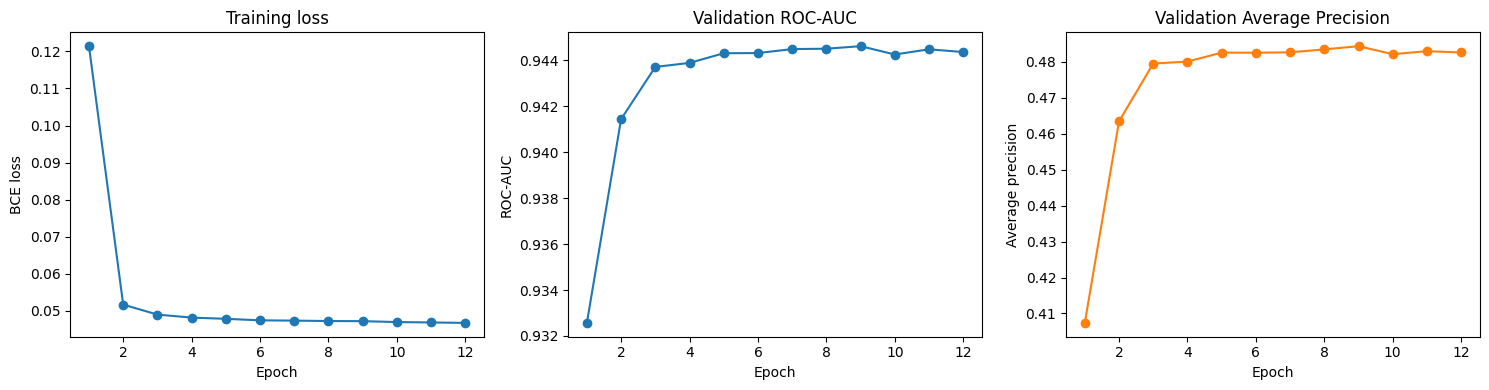

{
  "task": "2.1 MLP baseline",
  "seed": 9,
  "split": "stratified 80/20",
  "n_train": 559968,
  "n_validation": 139992,
  "positive_rate_train": 0.01669916883111,
  "positive_rate_validation": 0.016700955107808113,
  "n_features_after_preprocessing": 54,
  "architecture": "54 -> 128 -> 64 -> 1, ReLU, dropout 0.20/0.10",
  "loss": "BCEWithLogitsLoss (unweighted baseline)",
  "best_epoch": 9,
  "epochs_run": 12,
  "validation_roc_auc": 0.9446222144255438,
  "validation_average_precision": 0.48434002468821485,
  "device": "Tesla T4"
}
Saved files: ['best_model.pt', 'learning_curves.png', 'metrics.json', 'preprocessor.joblib', 'split_ids_seed9.csv', 'training_history.csv', 'validation_predictions_seed9.csv']


In [4]:
import json
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "training_history.csv", index=False)

validation_predictions = pd.DataFrame({
    ID_COL: train.iloc[valid_idx][ID_COL].to_numpy(),
    TARGET: y_valid.astype(np.int8),
    "fraud_probability": best_valid_prob.astype(np.float32),
})
validation_predictions.to_csv(OUTPUT_DIR / "validation_predictions_seed9.csv", index=False)

metrics = {
    "task": "2.1 MLP baseline",
    "seed": SEED,
    "split": "stratified 80/20",
    "n_train": int(len(train_idx)),
    "n_validation": int(len(valid_idx)),
    "positive_rate_train": float(y_train.mean()),
    "positive_rate_validation": float(y_valid.mean()),
    "n_features_after_preprocessing": int(X_train.shape[1]),
    "architecture": "54 -> 128 -> 64 -> 1, ReLU, dropout 0.20/0.10",
    "loss": "BCEWithLogitsLoss (unweighted baseline)",
    "best_epoch": int(best_epoch),
    "epochs_run": int(len(history)),
    "validation_roc_auc": float(roc_auc_score(y_valid, best_valid_prob)),
    "validation_average_precision": float(average_precision_score(y_valid, best_valid_prob)),
    "device": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
}
with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o")
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="BCE loss")
axes[1].plot(history_df["epoch"], history_df["val_roc_auc"], marker="o", color="tab:blue")
axes[1].set(title="Validation ROC-AUC", xlabel="Epoch", ylabel="ROC-AUC")
axes[2].plot(history_df["epoch"], history_df["val_average_precision"], marker="o", color="tab:orange")
axes[2].set(title="Validation Average Precision", xlabel="Epoch", ylabel="Average precision")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "learning_curves.png", dpi=160, bbox_inches="tight")
plt.show()

print(json.dumps(metrics, indent=2))
print("Saved files:", sorted(path.name for path in OUTPUT_DIR.iterdir()))
